# Model Blending and Weight Optimization

## Ensemble Meta-Model with Optuna-Based Weight Optimization 

### Overview
This notebook builds a stacked ensemble (meta-model) that combines out-of-fold (OOF) and test predictions from multiple base models.
For the metamodel, I’ve used the best models, fine-tuned with scripts from my GitHub repository. Weights are optimized with Optuna to maximize ROC AUC, using two blending strategies:

- **Probability blending** — weighted average of predicted probabilities
- **Logit blending** — weighted average in log-odds space, followed by a sigmoid transform

### Pipeline
1. Load ground-truth labels from `training.csv` and predictions from `../oof_predictions`
2. Optimize blend weights for both strategies via Optuna (TPE sampler, 100 trials)
3. Evaluate OOF ROC AUC for each blended ensemble
4. Save test predictions to `metamodel_probs_*.csv` and `metamodel_logits_*.csv`
5. Visualize pairwise model correlations in logit space (`model_correlations_logits.png`)
6. Report per-model weights, individual AUCs, and ensemble gains over the best single model

Loading data...

Loading predictions...
Found OOF files: 6
Found test files: 6
  OOF catboost_m0_est2980_cv0.79325: shape=(72983, 2), range=[0.0011, 0.9994]
  OOF lgbm_m0_est810_cv0.79430: shape=(72983, 2), range=[0.0028, 0.9937]
  OOF nn_ep26_cv0.78169: shape=(72983, 2), range=[0.0026, 0.9997]
  OOF xgb_drop_imp_m0_est730_cv0.75958: shape=(72983, 2), range=[0.0027, 0.9727]
  OOF xgb_m0_est350_cv0.79677: shape=(72983, 2), range=[0.0044, 0.9917]
  OOF xgb_unconfident_m0_est620_cv0.79252: shape=(72983, 2), range=[0.0034, 0.9950]
  Saved RefId from catboost_test_m0_est2980_cv0.79325.csv: 48707 records

Total models: 6
Models: ['catboost_m0_est2980_cv0.79325', 'lgbm_m0_est810_cv0.79430', 'nn_ep26_cv0.78169', 'xgb_drop_imp_m0_est730_cv0.75958', 'xgb_m0_est350_cv0.79677', 'xgb_unconfident_m0_est620_cv0.79252']

Optimizing weights for probability blending...
Best ROC AUC (probabilities): 0.802341

Optimizing weights for logit blending...
Best ROC AUC (logits): 0.802219

Saving results...
Test

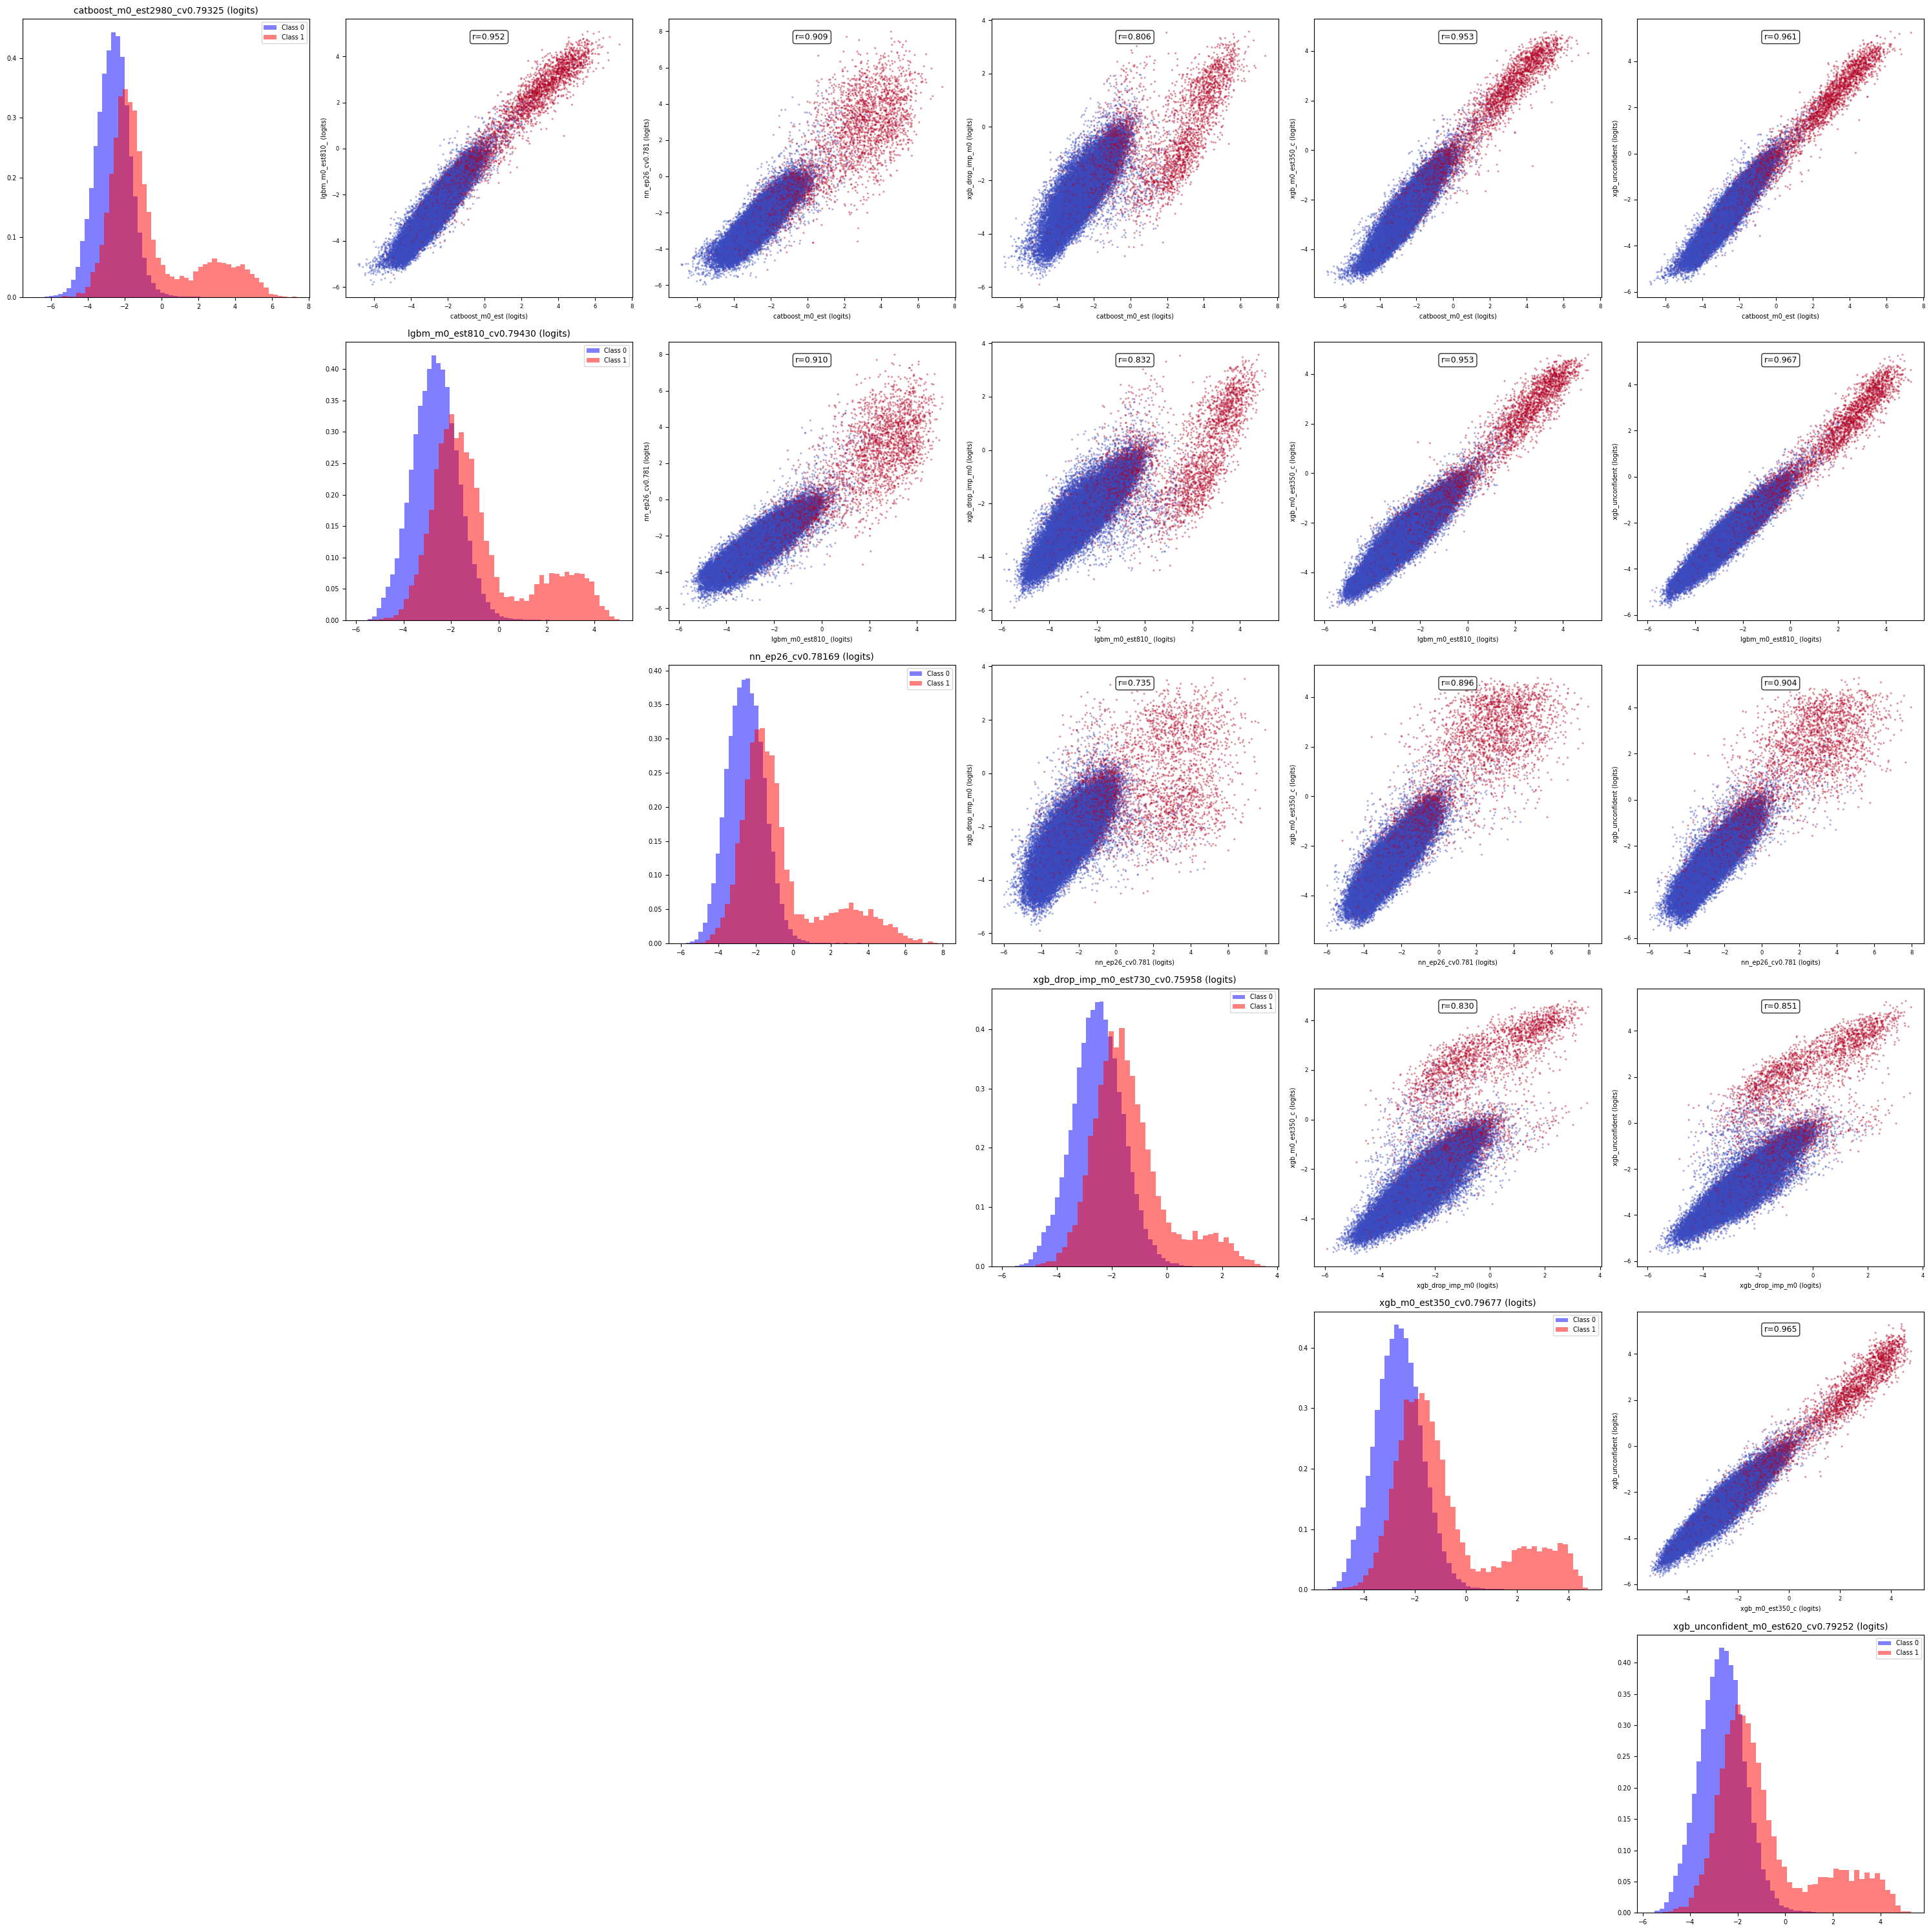


Summary statistics:
                              Model  Weight_Probs  Weight_Logits  Individual_AUC
      catboost_m0_est2980_cv0.79325      0.384021       0.362182        0.798905
            xgb_m0_est350_cv0.79677      0.344778       0.356233        0.797720
           lgbm_m0_est810_cv0.79430      0.167161       0.138100        0.794304
xgb_unconfident_m0_est620_cv0.79252      0.019870       0.020138        0.792519
                  nn_ep26_cv0.78169      0.019981       0.008889        0.781693
   xgb_drop_imp_m0_est730_cv0.75958      0.064189       0.114459        0.759585

Improvement over best individual model:
  Probabilities blending: +0.003436
  Logits blending: +0.003314

Final files:
  Probabilities: metamodel_probs_0_802341.csv (ROC AUC: 0.802341)
  Logits: metamodel_logits_0_802219.csv (ROC AUC: 0.802219)


In [2]:
import pandas as pd
import numpy as np
import optuna
from sklearn.metrics import roc_auc_score
from scipy.special import expit, logit
import matplotlib.pyplot as plt
import os
import glob
import warnings
warnings.filterwarnings('ignore')

optuna.logging.set_verbosity(optuna.logging.WARNING)

OOF_DIR = '../oof_predictions'
TRAIN_PATH = "../dont_get_kicked/datasets/training.csv"


print("Loading data...")
train_df = pd.read_csv(TRAIN_PATH)
y_true = train_df['IsBadBuy'].values
print("\nLoading predictions...")
oof_files = glob.glob(os.path.join(OOF_DIR, '*_oof_*.csv'))
test_files = glob.glob(os.path.join(OOF_DIR, '*_test_*.csv'))
print(f"Found OOF files: {len(oof_files)}")
print(f"Found test files: {len(test_files)}")
oof_preds = {}
test_preds = {}
test_ref_ids = None  

for oof_file in sorted(oof_files):
    basename = os.path.basename(oof_file)
    model_name = basename.replace('_oof_', '_').split('.csv')[0]
    df_oof = pd.read_csv(oof_file)
    oof_preds[model_name] = df_oof['IsBadBuy'].values
    print(f"  OOF {model_name}: shape={df_oof.shape}, range=[{df_oof['IsBadBuy'].min():.4f}, {df_oof['IsBadBuy'].max():.4f}]")

for test_file in sorted(test_files):
    basename = os.path.basename(test_file)
    model_name = basename.replace('_test_', '_').split('.csv')[0]
    df_test = pd.read_csv(test_file)
    test_preds[model_name] = df_test['IsBadBuy'].values
    if test_ref_ids is None and 'RefId' in df_test.columns:
        test_ref_ids = df_test['RefId'].values
        print(f"  Saved RefId from {basename}: {len(test_ref_ids)} records")

model_names = list(oof_preds.keys())
n_models = len(model_names)
print(f"\nTotal models: {n_models}")
print(f"Models: {model_names}")
for name in model_names:
    assert len(oof_preds[name]) == len(y_true), f"Size mismatch for {name}"

def blend_probabilities(weights, preds_dict, model_list):
    sample_size = len(preds_dict[model_list[0]])
    blended = np.zeros(sample_size)
    for i, model in enumerate(model_list):
        blended += weights[i] * preds_dict[model]
    return blended

def blend_logits(weights, preds_dict, model_list):
    sample_size = len(preds_dict[model_list[0]])
    logits = {}
    for model in model_list:
        probs = np.clip(preds_dict[model], 1e-7, 1 - 1e-7)
        logits[model] = logit(probs)
    
    blended_logits = np.zeros(sample_size)
    for i, model in enumerate(model_list):
        blended_logits += weights[i] * logits[model]
    
    return expit(blended_logits)

print("\n" + "="*80)
print("Optimizing weights for probability blending...")
print("="*80)

def objective_probs(trial):
    weights = [trial.suggest_float(f'w_{i}', 0.0, 1.0) for i in range(n_models)]
    weight_sum = sum(weights)
    if weight_sum == 0:
        return 0.0
    weights_norm = [w / weight_sum for w in weights]
    
    blended = blend_probabilities(weights_norm, oof_preds, model_names)
    return roc_auc_score(y_true, blended)

study_probs = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study_probs.optimize(objective_probs, n_trials=100, show_progress_bar=False)

best_weights_probs = [study_probs.best_params[f'w_{i}'] for i in range(n_models)]
weight_sum = sum(best_weights_probs)
best_weights_probs_norm = [w / weight_sum for w in best_weights_probs]

best_oof_probs = blend_probabilities(best_weights_probs_norm, oof_preds, model_names)
best_roc_auc_probs = roc_auc_score(y_true, best_oof_probs)

print(f"Best ROC AUC (probabilities): {best_roc_auc_probs:.6f}")

print("\n" + "="*80)
print("Optimizing weights for logit blending...")
print("="*80)

def objective_logits(trial):
    weights = [trial.suggest_float(f'w_{i}', 0.0, 1.0) for i in range(n_models)]
    weight_sum = sum(weights)
    if weight_sum == 0:
        return 0.0
    weights_norm = [w / weight_sum for w in weights]
    
    blended = blend_logits(weights_norm, oof_preds, model_names)
    return roc_auc_score(y_true, blended)

study_logits = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study_logits.optimize(objective_logits, n_trials=100, show_progress_bar=False)

best_weights_logits = [study_logits.best_params[f'w_{i}'] for i in range(n_models)]
weight_sum = sum(best_weights_logits)
best_weights_logits_norm = [w / weight_sum for w in best_weights_logits]

best_oof_logits = blend_logits(best_weights_logits_norm, oof_preds, model_names)
best_roc_auc_logits = roc_auc_score(y_true, best_oof_logits)

print(f"Best ROC AUC (logits): {best_roc_auc_logits:.6f}")

print(f"\n{'='*80}")
print("Saving results...")
print(f"{'='*80}")

roc_auc_probs_str = f"{best_roc_auc_probs:.6f}".replace('.', '_')
output_filename_probs = f'metamodel_probs_{roc_auc_probs_str}.csv'

test_output_probs = pd.DataFrame({
    'RefId': test_ref_ids,
    'IsBadBuy': blend_probabilities(best_weights_probs_norm, test_preds, model_names)
})
test_output_probs.to_csv(output_filename_probs, index=False)
print(f"Test predictions (probabilities) saved to: {output_filename_probs}")

roc_auc_logits_str = f"{best_roc_auc_logits:.6f}".replace('.', '_')
output_filename_logits = f'metamodel_logits_{roc_auc_logits_str}.csv'

test_output_logits = pd.DataFrame({
    'RefId': test_ref_ids,
    'IsBadBuy': blend_logits(best_weights_logits_norm, test_preds, model_names)
})
test_output_logits.to_csv(output_filename_logits, index=False)
print(f"Test predictions (logits) saved to: {output_filename_logits}")

print("\nPreparing logits for visualization...")
oof_logits_dict = {}
for model in model_names:
    probs = np.clip(oof_preds[model], 1e-7, 1 - 1e-7)
    oof_logits_dict[model] = logit(probs)

print("Building visualization (scatterplot for logits)...")

cell_size = 5
fig, axes = plt.subplots(n_models, n_models, figsize=(cell_size * n_models, cell_size * n_models))

for i in range(n_models):
    for j in range(n_models):
        ax = axes[i, j]
        
        if i == j:
            # Диагональ: распределения логитов
            logits_model = oof_logits_dict[model_names[i]]
            mask_0 = y_true == 0
            mask_1 = y_true == 1
            
            ax.hist(logits_model[mask_0], bins=50, alpha=0.5, label='Class 0', color='blue', density=True)
            ax.hist(logits_model[mask_1], bins=50, alpha=0.5, label='Class 1', color='red', density=True)
            ax.set_title(f"{model_names[i]} (logits)", fontsize=10)
            ax.legend(fontsize=7)
            ax.tick_params(labelsize=7)
            
        elif j > i:
            logits_i = oof_logits_dict[model_names[i]]
            logits_j = oof_logits_dict[model_names[j]]
            
            corr = np.corrcoef(logits_i, logits_j)[0, 1]
            
            scatter = ax.scatter(logits_i, logits_j, c=y_true, cmap='coolwarm', alpha=0.3, s=2)
            
            ax.text(0.5, 0.95, f'r={corr:.3f}', transform=ax.transAxes,
                   fontsize=9, verticalalignment='top', horizontalalignment='center',
                   bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8))
            
            ax.set_xlabel(f"{model_names[i][:15]} (logits)", fontsize=7)
            ax.set_ylabel(f"{model_names[j][:15]} (logits)", fontsize=7)
            ax.tick_params(labelsize=6)
            
        else:
            ax.axis('off')

plt.tight_layout()
plt.savefig('model_correlations_logits.png', dpi=150, bbox_inches='tight')
print(f"Visualization saved to: model_correlations_logits.png")
plt.show()

print("\n" + "="*80)
print("Summary statistics:")
print("="*80)

results_summary = pd.DataFrame({
    'Model': model_names,
    'Weight_Probs': best_weights_probs_norm,
    'Weight_Logits': best_weights_logits_norm
})

individual_aucs = []
for model in model_names:
    auc = roc_auc_score(y_true, oof_preds[model])
    individual_aucs.append(auc)

results_summary['Individual_AUC'] = individual_aucs
results_summary = results_summary.sort_values('Individual_AUC', ascending=False)

print(results_summary.to_string(index=False))
print(f"\nImprovement over best individual model:")
print(f"  Probabilities blending: +{best_roc_auc_probs - max(individual_aucs):.6f}")
print(f"  Logits blending: +{best_roc_auc_logits - max(individual_aucs):.6f}")
print(f"\nFinal files:")
print(f"  Probabilities: {output_filename_probs} (ROC AUC: {best_roc_auc_probs:.6f})")
print(f"  Logits: {output_filename_logits} (ROC AUC: {best_roc_auc_logits:.6f})")

# Results

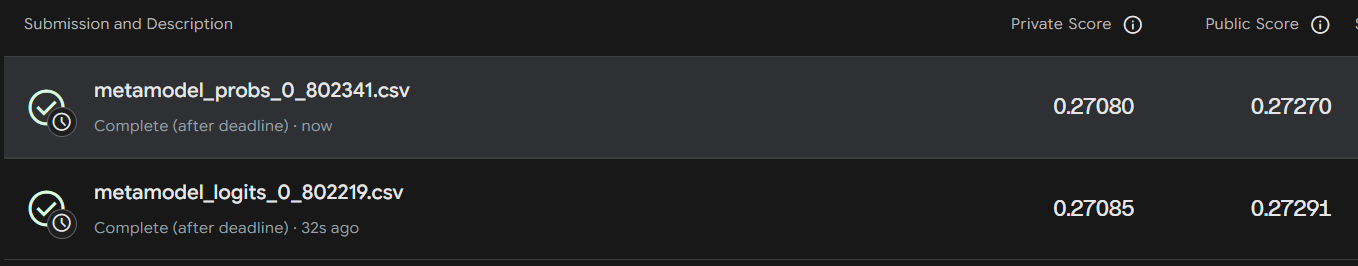